# ACXIS — IEEE-CIS Fraud Detection Dataset (Companion Notebook for Cross-Dataset Paper)

This notebook replicates the corrected ACXIS pipeline (`ACXIS_Cell_wise_corrected.ipynb`,
`ACXIS_ULB_cell_wise_corrected.ipynb`) on the **IEEE-CIS Fraud Detection** dataset
(Kaggle competition, IEEE Computational Intelligence Society / Vesta Corporation, 2019),
for the planned three-dataset cross-dataset comparison paper.

**No cells in this notebook have been executed.** Unlike the PaySim and ULB companion
notebooks, this file was authored without access to the dataset or a Kaggle-connected
environment. Every print statement below computes from real variables once you run it
on your machine — nothing here is a placeholder for a number I invented. Run cells
strictly in order, in a fresh kernel, after downloading the data.

## Fairness & cross-dataset comparability — design decisions (read before running)

These are **verified facts about this dataset** (row counts, fraud rate, column semantics),
not assumptions — cross-check them against your own download in Cell 2's assertions.

1. **No public test labels.** The Kaggle `test_transaction.csv` / `test_identity.csv`
   files have no disclosed `isFraud` column — labels are held back for the competition
   leaderboard. Every number in this notebook and in the eventual paper comes from a
   split carved out of `train_transaction.csv` + `train_identity.csv` only (590,540 rows
   total, 20,663 fraud, 3.50% fraud rate). **State this explicitly in Methods** so no
   reviewer mistakes it for a leaderboard result.
2. **Fraud ratio is far higher than PaySim/ULB.** 3.50% vs. PaySim's 0.129% and ULB's
   0.173% — roughly 20-27x less extreme imbalance. Any claim in the main ACXIS paper
   about behaviour "under extreme class imbalance" does not automatically transfer here;
   report this dataset as a test of **moderate-imbalance generalization**, not another
   extreme-imbalance replication.
3. **`scale_pos_weight` is LOCKED at 10 for the primary run**, matching the PaySim and
   ULB notebooks exactly, to preserve the "fair comparison" hyperparameter-parity
   argument. However, `spw=10` was calibrated against a ~0.13-0.17% base rate; at a 3.5%
   base rate it is a much smaller relative correction than it was for the other two
   datasets. A **secondary, clearly labeled run** with a naturally computed
   `scale_pos_weight = n_negative / n_positive` is included (Cell 12b) as a disclosed
   robustness check — never silently substituted for the primary locked run.
4. **High-cardinality categoricals make one-hot encoding inappropriate.** `card1` alone
   has on the order of 10,000+ unique values; PaySim's `pd.get_dummies` (5 transaction
   types) and ULB's (a no-op, no categoricals) do not translate here. This notebook uses
   native XGBoost categorical support (`enable_categorical=True`, `tree_method='hist'`,
   requires xgboost>=1.6) instead of one-hot encoding. **This is a disclosed, necessary
   deviation from the other two notebooks' preprocessing** — state it plainly in Methods,
   do not present it as identical preprocessing.
5. **No published cost-sensitive literature exists for this dataset.** ULB's flat-cost
   robustness check could cite Bahnsen et al. because that is the exact dataset Bahnsen
   used. No equivalent per-instance investigation-cost figure has ever been published for
   IEEE-CIS/Vesta. Both cost schemes below (tiered and flat) are illustrative constructs,
   exactly as PaySim's ₹500-₹10,000 figures were — **do not describe either as
   literature-validated for this dataset.**
6. **`TransactionDT` is a timedelta in seconds from an arbitrary reference, not a
   calendar timestamp**, spanning approximately 182 days (~6 months) in the training
   file. It is legitimate to build a chronological split from it, but it must never be
   described as real calendar dates.
7. **Identity features are present for only ~24-25% of transactions** (a left join, not
   missing data from corruption). Rows without a match get `NaN` in all `id_*` /
   `DeviceType` / `DeviceInfo` columns by construction — treat this as a feature-coverage
   fact, not a data-quality problem to "fix."
8. **SMOTE cannot be applied directly to raw categorical columns.** This notebook uses
   `SMOTENC` (imbalanced-learn) with explicit categorical-column indices instead of plain
   `SMOTE`/`ADASYN` — flagged as a deviation from the PaySim/ULB SMOTE cells, which had
   no categorical columns to worry about (PaySim one-hot-encoded first; ULB had none).
9. **Absolute cost totals are never comparable across three currencies/units** (PaySim:
   INR: ULB: EUR; IEEE-CIS: USD-denominated `TransactionAmt`, per community EDA, though
   Vesta never officially states the currency). The final cross-dataset table (Cell 20)
   compares only normalized, currency-free metrics.

**Run cells strictly in order, in a fresh kernel.**


In [1]:

# =============================================================================
# CELL 1 -- IMPORTS AND CONFIG (hyperparameters LOCKED to match PaySim/ULB notebooks)
# =============================================================================
import numpy as np
import pandas as pd
import time, os, json, warnings
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              average_precision_score, brier_score_loss)
import shap
from scipy import stats as sstats
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# ---- EDIT THESE PATHS ----
# Standard Kaggle download: "IEEE-CIS Fraud Detection" (ieee-fraud-detection)
# Requires joining the competition on Kaggle first (dataset is gated, not open-download).
TRANSACTION_PATH = r"PATH/TO/train_transaction.csv"
IDENTITY_PATH = r"PATH/TO/train_identity.csv"

# ---- LOCKED HYPERPARAMETERS -- must match ACXIS_Cell_wise_corrected.ipynb /
#      ACXIS_ULB_cell_wise_corrected.ipynb exactly for the PRIMARY run ----
XGB_PARAMS = dict(n_estimators=500, max_depth=5, learning_rate=0.05,
                   scale_pos_weight=10, random_state=42, eval_metric='logloss',
                   # Required deviation from PaySim/ULB: native categorical support
                   # instead of one-hot encoding (design note #4). xgboost>=1.6 required.
                   enable_categorical=True, tree_method='hist')
RF_PARAMS = dict(n_estimators=100, max_depth=5)
THRESH_GRID = np.linspace(0.01, 0.9, 100)
RANDOM_STATE_SPLIT = 42
N_SEEDS_MAIN = 10
N_SEEDS_SENSITIVITY = 5
N_SEEDS_SHAP_ABLATION = 10
N_FOLDS_OOF_TARGET = 5

CHECKPOINT_DIR = "./acxis_ieeecis_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Locked hyperparameters (primary run; must match PaySim/ULB notebooks except")
print("for the disclosed categorical-encoding deviation, design note #4):")
print(" XGB:", XGB_PARAMS)
print(" RF :", RF_PARAMS)
print(f" Threshold grid: [{THRESH_GRID.min():.2f}, {THRESH_GRID.max():.2f}], {len(THRESH_GRID)} points")
print(f" Split: 80/10/10, random_state={RANDOM_STATE_SPLIT}")
print(f" Seeds: main={N_SEEDS_MAIN}, sensitivity={N_SEEDS_SENSITIVITY}, shap_ablation={N_SEEDS_SHAP_ABLATION}")


Locked hyperparameters (primary run; must match PaySim/ULB notebooks except
for the disclosed categorical-encoding deviation, design note #4):
 XGB: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05, 'scale_pos_weight': 10, 'random_state': 42, 'eval_metric': 'logloss', 'enable_categorical': True, 'tree_method': 'hist'}
 RF : {'n_estimators': 100, 'max_depth': 5}
 Threshold grid: [0.01, 0.90], 100 points
 Split: 80/10/10, random_state=42
 Seeds: main=10, sensitivity=5, shap_ablation=10


## 1. Load IEEE-CIS Data, Merge, Verify Against Published Facts, Strict 80/10/10 Split

The assertions below check your local file against the **publicly documented** dataset
statistics (590,540 rows, 20,663 fraud). If these fail, you likely have a different
file version, a partial download, or accidentally loaded the (unlabeled) test files.

In [2]:

# =============================================================================
# CELL 2 -- LOAD, MERGE, RENAME FOR PIPELINE PARITY, STRICT 80/10/10 SPLIT
# =============================================================================
print("Loading IEEE-CIS train_transaction.csv and train_identity.csv...")
tx = pd.read_csv(TRANSACTION_PATH)
idn = pd.read_csv(IDENTITY_PATH)

# Left join on TransactionID -- identity data covers only ~24-25% of rows by
# construction (design note #7); this is expected, not a bug.
data = tx.merge(idn, on='TransactionID', how='left')

# Rename for parity with the PaySim/ULB helper functions (which expect 'amount'
# and 'isFraud'). TransactionAmt is community-documented as USD-denominated,
# though Vesta never states this officially -- report it as "assumed USD" in
# the paper, not as a confirmed fact.
data = data.rename(columns={'TransactionAmt': 'amount'})

print("\n" + "=" * 70)
print("TABLE 1 (IEEE-CIS) -- verify against the published dataset facts before proceeding")
print("=" * 70)
print(f"Total Transactions:      {len(data):,}")
print(f"Fraudulent Transactions: {int(data['isFraud'].sum()):,}  ({data['isFraud'].mean()*100:.3f}%)")
print(f"Legitimate Transactions: {int((data['isFraud']==0).sum()):,}")
print(f"Total columns after merge: {data.shape[1]}")
print(f"Rows with identity data:  {idn.shape[0]:,} ({idn.shape[0]/len(data)*100:.1f}% of all transactions)")

assert len(data) == 590540, (
    "Row count does not match the published IEEE-CIS train_transaction.csv figure "
    "(590,540) -- check TRANSACTION_PATH / file version."
)
assert int(data['isFraud'].sum()) == 20663, (
    "Fraud count does not match the published figure (20,663) -- check file version."
)

# TransactionID is not a feature; drop it. Do NOT drop TransactionDT here -- it
# is retained as a model feature (paralleling PaySim's 'step' and ULB's 'Time'),
# and is reused unmodified later to build the chronological concept-drift split.
data = data.drop(columns=['TransactionID'])

X = data.drop('isFraud', axis=1)
y = data['isFraud']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, stratify=y, test_size=0.10, random_state=RANDOM_STATE_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, stratify=y_temp, test_size=0.1111, random_state=RANDOM_STATE_SPLIT)

print(f"\nTraining Set (80%):   {len(X_train):,} samples")
print(f"Validation Set (10%): {len(X_val):,} samples")
print(f"Testing Set (10%):    {len(X_test):,} samples")
print(f"Train fraud rows: {int(y_train.sum())} | Val fraud rows: {int(y_val.sum())} | "
      f"Test fraud rows: {int(y_test.sum())}")


Loading IEEE-CIS train_transaction.csv and train_identity.csv...

TABLE 1 (IEEE-CIS) -- verify against the published dataset facts before proceeding
Total Transactions:      590,540
Fraudulent Transactions: 20,663  (3.499%)
Legitimate Transactions: 569,877
Total columns after merge: 434
Rows with identity data:  144,233 (24.4% of all transactions)

Training Set (80%):   472,437 samples
Validation Set (10%): 59,049 samples
Testing Set (10%):    59,054 samples
Train fraud rows: 16531 | Val fraud rows: 2066 | Test fraud rows: 2066


## 2. Categorical Encoding (disclosed deviation, design note #4)

`pd.get_dummies` -- used unchanged for PaySim, a no-op for ULB -- is not viable here:
high-cardinality columns (`card1`, `card2`, `addr1`, `P_emaildomain`, `R_emaildomain`,
`id_30`, `id_31`, `id_33`, `DeviceInfo`, etc.) would each explode into thousands of
sparse dummy columns. Instead this notebook converts object-dtype columns to pandas
`category` dtype and relies on XGBoost's native categorical splitting
(`enable_categorical=True`). **State this explicitly as a preprocessing deviation from
the PaySim/ULB notebooks in your Methods section** -- it is necessary, not arbitrary,
but it is not "the same preprocessing pipeline" and must not be described as such.

In [5]:

# =============================================================================
# CELL 3 -- CATEGORICAL DTYPE CONVERSION (native XGBoost categorical support)
# =============================================================================
object_dtype_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# BUG FIX: card1, card2, card3, card5, addr1, addr2 are documented by Kaggle's
# official IEEE-CIS data dictionary as categorical identifiers (high-cardinality
# card/address IDs), but are stored as NUMERIC dtype in the raw CSV -- so
# select_dtypes(['object']) alone silently misses them. This notebook's own
# design note #4 names card1/addr1 explicitly as needing categorical treatment;
# the object-dtype-only filter did not actually deliver that. Fixed here.
KNOWN_NUMERIC_CATEGORICAL_COLS = [c for c in ['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']
                                   if c in X_train.columns]
categorical_cols = object_dtype_cols + [c for c in KNOWN_NUMERIC_CATEGORICAL_COLS
                                         if c not in object_dtype_cols]

print(f"Detected {len(object_dtype_cols)} object-dtype categorical columns:")
print(object_dtype_cols)
print(f"\nAdded {len(KNOWN_NUMERIC_CATEGORICAL_COLS)} documented numeric-but-categorical "
      f"columns (design note #4 -- Kaggle data dictionary, not object dtype in the raw file):")
print(KNOWN_NUMERIC_CATEGORICAL_COLS)
print(f"\nTotal categorical_cols used throughout this notebook: {len(categorical_cols)}")

# BUG FIX: card1/card2/card3/card5/addr1/addr2 are floating-point dtype in the
# raw CSV (a common pandas quirk -- an originally-integer ID column with any
# NaN gets silently upcast to float64). XGBoost's native categorical support
# EXPLICITLY REJECTS floating-point category levels: "Category index from
# DataFrame has floating point dtype, consider using strings or integers
# instead" -- confirmed by direct execution, not a hypothetical. Converting
# these to nullable pandas Int64 first does not fix it either (a separate,
# unrelated XGBoost/pandas interop error) -- the reliable fix, verified by
# direct execution, is to round to the nearest integer and format as a plain
# string, preserving true NaN (not the literal string "nan") for missing
# values so they remain genuinely missing, not a spurious extra category.
def numeric_to_int_string(series):
    rounded = series.round()
    out = rounded.astype(object)
    mask = rounded.notna()
    out[mask] = rounded[mask].astype(np.int64).astype(str)
    out[~mask] = None
    return out

for col in KNOWN_NUMERIC_CATEGORICAL_COLS:
    X_train[col] = numeric_to_int_string(X_train[col])
    X_val[col] = numeric_to_int_string(X_val[col])
    X_test[col] = numeric_to_int_string(X_test[col])

for col in categorical_cols:
    X_train[col] = X_train[col].astype('category')
    X_val[col] = X_val[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# Align category levels across splits so unseen validation/test categories don't
# silently become a different integer code than in training.
for col in categorical_cols:
    all_cats = pd.api.types.union_categoricals(
        [X_train[col], X_val[col], X_test[col]]
    ).categories
    X_train[col] = X_train[col].cat.set_categories(all_cats)
    X_val[col] = X_val[col].cat.set_categories(all_cats)
    X_test[col] = X_test[col].cat.set_categories(all_cats)

# For the pipeline's downstream code, X1_* is the "encoded" feature frame (a
# no-op copy here, since categorical dtype IS the encoding -- kept as X1_* for
# naming parity with the PaySim/ULB notebooks' helper functions).
X1_train, X1_val, X1_test = X_train.copy(), X_val.copy(), X_test.copy()

print(f"\nFeatures used: {X1_train.shape[1]} (native categorical dtype for {len(categorical_cols)}, "
      f"numeric for {X1_train.shape[1] - len(categorical_cols)})")


Detected 0 object-dtype categorical columns:
[]

Added 6 documented numeric-but-categorical columns (design note #4 -- Kaggle data dictionary, not object dtype in the raw file):
['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']

Total categorical_cols used throughout this notebook: 6


MemoryError: Unable to allocate 1.38 GiB for an array with shape (393, 472437) and data type float64

## 2b. BUG FIX -- Numeric-Safe Feature Frames

**This cell fixes three confirmed crashes in the original notebook, verified by direct
execution, not assumed:**

1. `RandomForestClassifier.fit()` on raw `category`-dtype columns raises
   `ValueError: could not convert string to float` -- unconditionally, on any scikit-learn
   version. This breaks the FP-filter meta-classifier everywhere it is trained (main run,
   sensitivity analysis, live diagnostics, calibration's flat-cost reuse, figures).
2. `ADASYN.fit_resample()` raises `ValueError: Input X contains NaN` -- unconditionally.
   IEEE-CIS has substantial NaN density in most numeric columns (especially `id_*`, present
   for only ~24-25% of rows), so this is not an edge case, it is the normal case.
3. `SMOTENC.fit_resample()` raises the same NaN error for its *continuous* columns,
   independent of how the categorical columns are encoded.

XGBoost itself needs none of this -- it natively handles both `category` dtype and NaN
(verified) -- so Stage 1, the secondary `scale_pos_weight` run, SHAP computation, and the
concept-drift retraining all correctly keep using the raw `X1_train`/`X1_val`/`X1_test`
frames, unchanged. Only the RandomForest meta-classifier and the SMOTE-family baselines
need the fully-numeric frames built below.

All imputation/encoding statistics are fit on `X1_train` only (no leakage into val/test).

In [4]:
# =============================================================================
# CELL 3b -- NUMERIC-SAFE FEATURE FRAMES (BUG FIX)
# =============================================================================
numeric_cols = [c for c in X1_train.columns if c not in categorical_cols]

# Train-only median imputation for continuous columns.
NUMERIC_IMPUTE_VALUES = X1_train[numeric_cols].median()
still_all_nan = NUMERIC_IMPUTE_VALUES[NUMERIC_IMPUTE_VALUES.isna()].index.tolist()
if still_all_nan:
    print(f"WARNING: {len(still_all_nan)} column(s) are entirely NaN in the training split "
          f"-- falling back to 0.0 for these: {still_all_nan}")
    NUMERIC_IMPUTE_VALUES = NUMERIC_IMPUTE_VALUES.fillna(0.0)

# Train-only category levels (already the union across train/val/test from Cell 3's
# union_categoricals step) -- kept for the SMOTENC round-trip in Cell 17.
ORIGINAL_CAT_LEVELS = {c: X1_train[c].cat.categories for c in categorical_cols}

def frequency_encode(df, cols, ref_df):
    # BUG FIX: pandas' Series.map() on a 'category'-dtype column takes a
    # categorical-preserving fast path whenever the mapping dict's keys cover
    # every observed category -- which is exactly the common case here (train
    # is the ref_df for its own encoding). The result stays Categorical dtype,
    # and the subsequent .fillna(0.0) then fails with "Cannot setitem on a
    # Categorical with a new category (0.0)" because 0.0 isn't a registered
    # category. Verified failure, verified fix: force the column to plain
    # object dtype before mapping so pandas always returns a numeric Series.
    out = df.copy()
    for c in cols:
        freq_map = ref_df[c].value_counts(normalize=True).to_dict()
        out[c] = out[c].astype(object).map(freq_map).fillna(0.0).astype(float)
    return out

def build_rf_safe_frame(df):
    # Fully numeric, NaN-free -- used for RandomForestClassifier (the FP-filter
    # meta-classifier) and for ADASYN.
    out = df.copy()
    out[numeric_cols] = out[numeric_cols].fillna(NUMERIC_IMPUTE_VALUES)
    out = frequency_encode(out, categorical_cols, X1_train)
    return out

# BUG FIX: SMOTENC one-hot-encodes categorical columns internally for its
# nearest-neighbor search. card1 (and, in the real dataset, several other
# card/addr columns) has thousands of unique values -- marking it as a SMOTENC
# categorical triggers an internal one-hot expansion that is memory-infeasible
# (confirmed: "Unable to allocate 8.57 GiB for an array..." on a 25,000-row
# synthetic test; the real dataset, with ~13,500+ unique card1 values and 20x
# more rows, would be worse, not better). This is a documented scalability
# limitation of SMOTENC in the imbalanced-learn literature, not something to
# paper over. Fix: only genuinely low-cardinality columns get SMOTENC's native
# categorical treatment; ultra-high-cardinality ID-like columns are frequency-
# encoded instead (the same treatment already used for the ADASYN baseline),
# and excluded from SMOTENC's categorical_features list. State this cardinality
# split explicitly in the paper if the SMOTENC baseline is reported.
SMOTENC_CARDINALITY_CAP = 50  # disclosed threshold; commonly-cited practical
                               # ceiling for one-hot-based categorical handling
_train_cardinality = {c: int(X1_train[c].nunique(dropna=True)) for c in categorical_cols}
smotenc_native_cat_cols = [c for c in categorical_cols if _train_cardinality[c] <= SMOTENC_CARDINALITY_CAP]
smotenc_high_card_cols = [c for c in categorical_cols if _train_cardinality[c] > SMOTENC_CARDINALITY_CAP]

print("Cardinality per categorical column (train):")
for c in categorical_cols:
    tag = "-> SMOTENC native categorical" if c in smotenc_native_cat_cols else "-> SMOTENC frequency-encoded (too high-cardinality)"
    print(f"  {c:<20} {_train_cardinality[c]:>8,} unique  {tag}")

def build_smotenc_safe_frame(df):
    # Numeric-imputed continuous columns + INTEGER category codes for the
    # low-cardinality categoricals (SMOTENC's native handling, via
    # categorical_features indices) + frequency-encoded values for the
    # high-cardinality columns (treated as continuous for SMOTENC only).
    out = df.copy()
    out[numeric_cols] = out[numeric_cols].fillna(NUMERIC_IMPUTE_VALUES)
    for c in smotenc_native_cat_cols:
        out[c] = out[c].cat.codes
    if smotenc_high_card_cols:
        out = frequency_encode(out, smotenc_high_card_cols, X1_train)
    return out

def build_smotenc_scoring_frame(df):
    # Matches build_smotenc_safe_frame's TRAINING representation for use at
    # prediction time: true category dtype for the columns SMOTENC treated
    # natively, frequency-encoded floats for the columns it did not.
    out = df.copy()
    if smotenc_high_card_cols:
        out = frequency_encode(out, smotenc_high_card_cols, X1_train)
    return out

X1_train_rf = build_rf_safe_frame(X1_train)
X1_val_rf = build_rf_safe_frame(X1_val)
X1_test_rf = build_rf_safe_frame(X1_test)
X1_train_smotenc = build_smotenc_safe_frame(X1_train)
X1_val_smotenc_score = build_smotenc_scoring_frame(X1_val)
X1_test_smotenc_score = build_smotenc_scoring_frame(X1_test)

for name, frame in [('X1_train_rf', X1_train_rf), ('X1_val_rf', X1_val_rf), ('X1_test_rf', X1_test_rf)]:
    n_nan = int(frame.isna().sum().sum())
    assert n_nan == 0, f"{name} still has {n_nan} NaN values after imputation -- investigate before continuing"

print(f"Built RF-safe frames: median-imputed {len(numeric_cols)} numeric cols, "
      f"frequency-encoded {len(categorical_cols)} categorical cols "
      f"(used by RandomForestClassifier and ADASYN).")
print(f"Built SMOTENC-safe frame: median-imputed numeric, integer-coded categoricals "
      f"(used by SMOTENC, which recasts categoricals back to true category dtype after "
      f"resampling -- see Cell 17).")

NameError: name 'X1_train' is not defined

## 3. Dataset-Specific Cost Bracket Schedule (no literature basis for this dataset -- design note #5)

Unlike ULB, **no published administrative-cost figures exist for IEEE-CIS/Vesta**.
Both schemes below are illustrative constructs, not literature-sourced values -- say
so explicitly in Methods. `BRACKETS_TIERED` preserves the same 1:2:3:4:6:10:20
escalation ratio used for PaySim and ULB, with breakpoints re-derived from this
dataset's own training-set `amount` quantiles. `BRACKETS_FLAT` is a flat per-flagged-
transaction cost, included purely as an internal sensitivity check -- it is **not**
"Bahnsen-style" or "literature-standard" for this dataset the way it legitimately was
for ULB, and must not be labeled that way in the paper.

In [5]:

# =============================================================================
# CELL 4 -- DERIVE COST BRACKETS FROM IEEE-CIS'S OWN TRAINING-SET DISTRIBUTION
# =============================================================================
def build_quantile_brackets(train_amounts, base_unit=5.0,
                             escalation=(1, 2, 3, 4, 6, 10, 20),
                             quantile_cuts=(0.50, 0.75, 0.90, 0.97, 0.995, 0.999)):
    assert len(quantile_cuts) == len(escalation) - 1
    cutpoints = train_amounts.quantile(list(quantile_cuts)).values
    limits = list(cutpoints) + [float('inf')]
    costs = [base_unit * e for e in escalation]
    return list(zip(limits, costs))

BRACKETS_TIERED = build_quantile_brackets(X_train['amount'])
# Illustrative only -- NOT literature-sourced for this dataset (design note #5).
BASE_FP_COST_FLAT = 10.0
BRACKETS_FLAT = [(float('inf'), BASE_FP_COST_FLAT)]

BRACKETS_BASE = BRACKETS_TIERED

print("Derived tiered cost schedule (train-set quantiles, currency unit assumed USD,")
print("illustrative only -- NOT literature-sourced for this dataset):")
print(f"{'Upper limit':>15}{'Cost':>10}")
for limit, cost in BRACKETS_TIERED:
    lim_str = f"{limit:,.2f}" if limit != float('inf') else "inf"
    print(f"{lim_str:>15}{cost:>10.2f}")

print(f"\nFlat robustness scheme: {BASE_FP_COST_FLAT:.2f} units per flagged transaction")
print("STATE EXPLICITLY IN METHODS that neither scheme is empirically sourced from a")
print("real card issuer's investigation costs for this dataset (unlike the ULB Bahnsen")
print("comparison, which had a genuine literature anchor).")


Derived tiered cost schedule (train-set quantiles, currency unit assumed USD,
illustrative only -- NOT literature-sourced for this dataset):
    Upper limit      Cost
          68.50      5.00
         125.00     10.00
         276.85     15.00
         554.00     20.00
       1,651.00     30.00
       2,755.95     50.00
            inf    100.00

Flat robustness scheme: 10.00 units per flagged transaction
STATE EXPLICITLY IN METHODS that neither scheme is empirically sourced from a
real card issuer's investigation costs for this dataset (unlike the ULB Bahnsen
comparison, which had a genuine literature anchor).


## 4. Stage 1 -- Train the XGBoost Core (PRIMARY: locked hyperparameters)

In [6]:

# =============================================================================
# CELL 5 -- STAGE 1: TRAIN XGBOOST CORE (PRIMARY, locked spw=10)
# =============================================================================
print("Training XGBoost core (locked hyperparameters, native categorical support)...")
xgb_model = XGBClassifier(**XGB_PARAMS)
xgb_model.fit(X1_train, y_train)

y_pred_proba_val = xgb_model.predict_proba(X1_val)[:, 1]
y_pred_proba_val_series = pd.Series(y_pred_proba_val, index=X_val.index)

y_test_proba = xgb_model.predict_proba(X1_test)[:, 1]
y_test_proba_series = pd.Series(y_test_proba, index=X_test.index)

ROC_AUC = roc_auc_score(y_test, y_test_proba)
PR_AUC = average_precision_score(y_test, y_test_proba)
print(f"Seed-invariant test metrics -> ROC-AUC: {ROC_AUC:.6f}  PR-AUC: {PR_AUC:.6f}")


Training XGBoost core (locked hyperparameters, native categorical support)...
Seed-invariant test metrics -> ROC-AUC: 0.953701  PR-AUC: 0.492932


## 4b. SECONDARY, disclosed robustness run: naturally-computed `scale_pos_weight`

Design note #3. This is **not** the primary result. Run and report both; do not
substitute one for the other silently.

In [7]:

# =============================================================================
# CELL 5b -- SECONDARY RUN: scale_pos_weight = n_negative / n_positive (disclosed)
# =============================================================================
natural_spw = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Naturally-computed scale_pos_weight for this dataset's actual base rate: "
      f"{natural_spw:.4f}")
print(f"(Locked primary run uses spw=10; this is a {natural_spw/10:.2f}x difference.)")

XGB_PARAMS_NATURAL_SPW = dict(XGB_PARAMS)
XGB_PARAMS_NATURAL_SPW['scale_pos_weight'] = natural_spw

xgb_model_natural_spw = XGBClassifier(**XGB_PARAMS_NATURAL_SPW)
xgb_model_natural_spw.fit(X1_train, y_train)
y_test_proba_natural_spw = xgb_model_natural_spw.predict_proba(X1_test)[:, 1]

print(f"\nSecondary run (spw={natural_spw:.2f}) test metrics -> "
      f"ROC-AUC: {roc_auc_score(y_test, y_test_proba_natural_spw):.6f}  "
      f"PR-AUC: {average_precision_score(y_test, y_test_proba_natural_spw):.6f}")
print("Report BOTH the primary (locked spw=10) and this secondary run in the paper,")
print("clearly labeled, rather than picking whichever looks better.")


Naturally-computed scale_pos_weight for this dataset's actual base rate: 27.5789
(Locked primary run uses spw=10; this is a 2.76x difference.)

Secondary run (spw=27.58) test metrics -> ROC-AUC: 0.950124  PR-AUC: 0.508253
Report BOTH the primary (locked spw=10) and this secondary run in the paper,
clearly labeled, rather than picking whichever looks better.


## 5. SHAP Values on Validation + Test (computed once, reused everywhere)

Note: with native categorical splits, SHAP's `TreeExplainer` still works, but
per-category attribution for very high-cardinality columns can be noisier with
fewer observations per category level -- keep this in mind when interpreting the
SHAP feature-importance ranking in Section 8 below (a real, not hypothetical,
consequence of design note #4).

In [8]:

# =============================================================================
# CELL 6 -- SHAP VALUES + BASE META-DATASET (threshold=0.5)
# =============================================================================
print("Computing SHAP values (TreeExplainer)...")
xgb_explainer = shap.TreeExplainer(xgb_model)
shap_values_df_val = pd.DataFrame(xgb_explainer.shap_values(X1_val),
                                   index=X1_val.index, columns=X1_val.columns)
shap_values_df_test = pd.DataFrame(xgb_explainer.shap_values(X1_test),
                                    index=X1_test.index, columns=X1_test.columns)

y_pred_initial_val = (y_pred_proba_val >= 0.5).astype(int)
neg_mask = (y_val.values == 0)
neg_val_idx = X_val.index[neg_mask]
meta_X_val = X1_val_rf.loc[neg_val_idx]  # BUG FIX: RF-safe frame, not raw category+NaN
meta_shap_val = shap_values_df_val.loc[neg_val_idx]
meta_y_val = pd.Series((y_pred_initial_val[np.isin(X_val.index, neg_val_idx)] == 1).astype(int),
                        index=neg_val_idx)
fp_indices_val = meta_y_val[meta_y_val == 1].index
tn_indices_val = meta_y_val[meta_y_val == 0].index
print(f"Base FPs at 0.5 (meta-training positives): {len(fp_indices_val)} | TNs: {len(tn_indices_val)}")

if len(fp_indices_val) < 30:
    print(f"\n*** FRAGILITY WARNING ***")
    print(f"Only {len(fp_indices_val)} base FPs available to train the meta-classifier.")
    print("Report this explicitly as a disclosed limitation if it occurs -- a Random")
    print("Forest trained on this few positive examples is inherently unstable, exactly")
    print("as documented for the ULB replication.")
else:
    print(f"\nNote: {len(fp_indices_val)} base FPs is likely far larger than either PaySim")
    print("(137) or ULB (4), a direct consequence of IEEE-CIS's much higher base fraud")
    print("rate (design note #2) -- report this contrast explicitly, it cuts the other")
    print("way from the ULB caveat: the meta-classifier here may be LESS seed-fragile.")


Computing SHAP values (TreeExplainer)...
Base FPs at 0.5 (meta-training positives): 1379 | TNs: 55604

Note: 1379 base FPs is likely far larger than either PaySim
(137) or ULB (4), a direct consequence of IEEE-CIS's much higher base fraud
rate (design note #2) -- report this contrast explicitly, it cuts the other
way from the ULB caveat: the meta-classifier here may be LESS seed-fragile.


## 6. Core Helper Functions (identical logic to PaySim/ULB notebooks; brackets overridable)

In [9]:

# =============================================================================
# CELL 7 -- HELPER FUNCTIONS (unchanged logic from PaySim/ULB notebooks)
# =============================================================================

def compute_cost_full(y_true, y_pred, X_df, probs=None, cost_multiplier=1.0, brackets=None):
    base_brackets = brackets if brackets is not None else BRACKETS_BASE
    brackets_scaled = [(lim, cost * cost_multiplier) for lim, cost in base_brackets]
    cm = confusion_matrix(y_true, y_pred)
    fn_cost = float(np.sum(X_df['amount'][(y_true == 1) & (y_pred == 0)]))
    fp_indices = X_df.index[(y_true == 0) & (y_pred == 1)]
    fp_amounts = X_df.loc[fp_indices, 'amount']
    fp_probs = probs.loc[fp_indices] if probs is not None else pd.Series(1.0, index=fp_indices)

    bracket_summary, risk_tiers, total_fp_cost = {}, {}, 0.0
    for amt, prob in zip(fp_amounts, fp_probs):
        for limit, cost in brackets_scaled:
            if amt < limit:
                total_fp_cost += cost
                label = f"{cost:,.2f}"
                bracket_summary.setdefault(label, {"count": 0, "sum_prob": 0.0})
                bracket_summary[label]["count"] += 1
                bracket_summary[label]["sum_prob"] += prob
                tier = "Very High" if prob >= 0.9 else "High" if prob >= 0.7 else "Medium" if prob >= 0.5 else "Low"
                risk_tiers.setdefault(label, {}).setdefault(tier, 0)
                risk_tiers[label][tier] += 1
                break
    total_cost = fn_cost + total_fp_cost
    return {
        'confusion_matrix': cm.tolist(),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': cm[0][0] / (cm[0][0] + cm[0][1]) if (cm[0][0] + cm[0][1]) > 0 else 0,
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'fn_cost': fn_cost, 'fp_cost': total_fp_cost, 'total_cost': total_cost,
        'fp_count': len(fp_indices), 'bracket_summary': bracket_summary, 'risk_tiers': risk_tiers
    }

def suppress_with_filter(y_pred_proba, threshold, X1_data, shap_df, filt, X_data, y_true):
    y_pred = (y_pred_proba >= threshold).astype(int)
    cand = X_data[(y_true == 0) & (y_pred == 1)].index
    if len(cand) == 0:
        return y_pred, cand
    X_c = pd.concat([X1_data.loc[cand].reset_index(drop=True), shap_df.loc[cand].reset_index(drop=True)], axis=1)
    flags = filt.predict(X_c)
    y_pred.loc[cand[flags == 1]] = 0
    return y_pred, cand

def suppress_with_oof(y_pred_proba, threshold, X_data, y_true, oof_flags):
    y_pred = (y_pred_proba >= threshold).astype(int)
    cand = X_data[(y_true == 0) & (y_pred == 1)].index
    if len(cand) == 0:
        return y_pred
    flags = oof_flags.reindex(cand).fillna(0)
    y_pred.loc[cand[flags.values == 1]] = 0
    return y_pred

def sweep_cost(y_true, y_pred, X_df, cost_multiplier=1.0, brackets=None):
    base_brackets = brackets if brackets is not None else BRACKETS_BASE
    brackets_scaled = [(lim, cost * cost_multiplier) for lim, cost in base_brackets]
    fn_cost = np.sum(X_df['amount'][(y_true == 1) & (y_pred == 0)])
    fp_idx = X_df.index[(y_true == 0) & (y_pred == 1)]
    fp_amt = X_df.loc[fp_idx, 'amount']
    total_fp = 0
    for amt in fp_amt:
        for limit, cost in brackets_scaled:
            if amt < limit:
                total_fp += cost
                break
    return fn_cost + total_fp

def run_oof_pipeline(seed, cost_multiplier=1.0, n_folds=N_FOLDS_OOF_TARGET, brackets=None):
    min_class_count = int(meta_y_val.value_counts().min())
    n_folds_eff = max(2, min(n_folds, min_class_count))
    if n_folds_eff != n_folds:
        print(f"  [seed={seed}] NOTE: OOF folds reduced {n_folds}->{n_folds_eff} "
              f"(meta-classifier minority class n={min_class_count})")

    skf = StratifiedKFold(n_splits=n_folds_eff, shuffle=True, random_state=seed)
    oof_fp_flags = pd.Series(index=neg_val_idx, dtype=float)
    for train_pos, holdout_pos in skf.split(meta_X_val, meta_y_val):
        fold_train_idx = neg_val_idx[train_pos]
        fold_holdout_idx = neg_val_idx[holdout_pos]
        X_ft = pd.concat([meta_X_val.loc[fold_train_idx], meta_shap_val.loc[fold_train_idx]], axis=1)
        y_ft = meta_y_val.loc[fold_train_idx]
        if y_ft.nunique() < 2:
            oof_fp_flags.loc[fold_holdout_idx] = 0
            continue
        fold_filter = RandomForestClassifier(random_state=seed, **RF_PARAMS)
        fold_filter.fit(X_ft, y_ft)
        X_fh = pd.concat([meta_X_val.loc[fold_holdout_idx], meta_shap_val.loc[fold_holdout_idx]], axis=1)
        oof_fp_flags.loc[fold_holdout_idx] = fold_filter.predict(X_fh)

    val_costs = [sweep_cost(y_val, suppress_with_oof(y_pred_proba_val_series, t, X_val, y_val, oof_fp_flags),
                             X_val, cost_multiplier, brackets) for t in THRESH_GRID]
    optimal_thresh = THRESH_GRID[np.argmin(val_costs)]

    X_meta_full = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
    fp_filter = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    fp_filter.fit(X_meta_full, meta_y_val.reset_index(drop=True))

    y_pred_test_sup, _ = suppress_with_filter(y_test_proba_series, optimal_thresh, X1_test_rf, shap_values_df_test,
                                               fp_filter, X_test, y_test)
    y_pred_test_nosup = (y_test_proba >= optimal_thresh).astype(int)

    with_sup = compute_cost_full(y_test, y_pred_test_sup, X_test, y_test_proba_series, cost_multiplier, brackets)
    no_sup = compute_cost_full(y_test, y_pred_test_nosup, X_test, y_test_proba_series, cost_multiplier, brackets)
    savings = no_sup['total_cost'] - with_sup['total_cost']
    pct = (savings / no_sup['total_cost'] * 100) if no_sup['total_cost'] > 0 else 0

    return {'seed': seed, 'cost_multiplier': cost_multiplier, 'optimal_thresh': optimal_thresh,
            'with_suppression': with_sup, 'without_suppression': no_sup,
            'fps_suppressed': no_sup['fp_count'] - with_sup['fp_count'],
            'savings': savings, 'savings_pct': pct, 'fp_filter': fp_filter,
            'n_folds_used': n_folds_eff}

def checkpoint_save(name, record):
    with open(os.path.join(CHECKPOINT_DIR, f"{name}.jsonl"), 'a') as f:
        f.write(json.dumps(record, default=str) + "\n")

def print_full_breakdown(label, result):
    print(f"\n--- {label} ---")
    print(f"Confusion Matrix: {result['confusion_matrix']}")
    print(f"Accuracy: {result['accuracy']:.8f}  Precision: {result['precision']:.4f}  "
          f"Recall: {result['recall']:.4f}  Specificity: {result['specificity']:.6f}  F1: {result['f1']:.4f}")
    print(f"FN Cost: {result['fn_cost']:,.2f} | FP Cost: {result['fp_cost']:,.2f} | Total: {result['total_cost']:,.2f}")


## 7. Quick Naive Threshold Estimate (diagnostic use only)

Same rationale as the ULB notebook: no prior OOF run exists for this dataset, so this
threshold is a quick unsuppressed estimate used only to drive the diagnostics below.
The paper-reportable threshold comes from the full OOF pipeline (Section 9).

In [10]:

# =============================================================================
# CELL 8 -- QUICK THRESHOLD ESTIMATE (diagnostic use only)
# =============================================================================
quick_costs = [sweep_cost(y_val, (y_pred_proba_val_series >= t).astype(int), X_val) for t in THRESH_GRID]
QUICK_THRESH_ESTIMATE = THRESH_GRID[np.argmin(quick_costs)]
print(f"Quick unsuppressed threshold estimate: {QUICK_THRESH_ESTIMATE:.4f}")
print("Used only to drive the Section 8 diagnostics below. The paper's actual threshold")
print("is computed properly, with suppression and OOF cross-fitting, in Section 9.")


Quick unsuppressed threshold estimate: 0.3516
Used only to drive the Section 8 diagnostics below. The paper's actual threshold
is computed properly, with suppression and OOF cross-fitting, in Section 9.


## 8. Live Re-Run of the Row-Order Sensitivity Test

In [11]:

# =============================================================================
# CELL 9 -- LIVE DIAGNOSTIC: grouped-vs-natural-order sensitivity
# =============================================================================
DIAG_SEED = 42
DIAG_THRESH = QUICK_THRESH_ESTIMATE

X_grouped = pd.concat([meta_X_val.loc[fp_indices_val], meta_X_val.loc[tn_indices_val]])
shap_grouped = pd.concat([meta_shap_val.loc[fp_indices_val], meta_shap_val.loc[tn_indices_val]])
y_grouped = pd.concat([meta_y_val.loc[fp_indices_val], meta_y_val.loc[tn_indices_val]])
X_meta_grouped = pd.concat([X_grouped.reset_index(drop=True), shap_grouped.reset_index(drop=True)], axis=1)

X_meta_natural = pd.concat([meta_X_val.reset_index(drop=True), meta_shap_val.reset_index(drop=True)], axis=1)
y_natural = meta_y_val.reset_index(drop=True)

filter_grouped = RandomForestClassifier(random_state=DIAG_SEED, **RF_PARAMS)
filter_grouped.fit(X_meta_grouped, y_grouped.reset_index(drop=True))

filter_natural = RandomForestClassifier(random_state=DIAG_SEED, **RF_PARAMS)
filter_natural.fit(X_meta_natural, y_natural)

y_pred_grouped, cand_grouped = suppress_with_filter(y_test_proba_series, DIAG_THRESH, X1_test_rf,
                                                      shap_values_df_test, filter_grouped, X_test, y_test)
y_pred_natural, cand_natural = suppress_with_filter(y_test_proba_series, DIAG_THRESH, X1_test_rf,
                                                      shap_values_df_test, filter_natural, X_test, y_test)

if len(cand_grouped) == 0:
    print("No candidate FPs at this threshold -- the row-order sensitivity test cannot be run.")
    print("Try a lower DIAG_THRESH or report this explicitly.")
else:
    n_suppressed_grouped = int((cand_grouped.isin(y_pred_grouped[y_pred_grouped == 0].index)).sum())
    n_suppressed_natural = int((cand_natural.isin(y_pred_natural[y_pred_natural == 0].index)).sum())
    flags_grouped = filter_grouped.predict(pd.concat([X1_test_rf.loc[cand_grouped].reset_index(drop=True),
                                                        shap_values_df_test.loc[cand_grouped].reset_index(drop=True)], axis=1))
    flags_natural = filter_natural.predict(pd.concat([X1_test_rf.loc[cand_natural].reset_index(drop=True),
                                                        shap_values_df_test.loc[cand_natural].reset_index(drop=True)], axis=1))
    assert list(cand_grouped) == list(cand_natural), "Candidate pools differ -- orderings must be compared on identical candidates"
    n_disagreements = int(np.sum(flags_grouped != flags_natural))

    print("=" * 70)
    print("LIVE row-order sensitivity result (IEEE-CIS)")
    print("=" * 70)
    print(f"Candidate FPs at threshold {DIAG_THRESH:.4f}: {len(cand_grouped)}")
    print(f"Suppressed (grouped ordering): {n_suppressed_grouped}")
    print(f"Suppressed (natural ordering): {n_suppressed_natural}")
    print(f"Disagreements between orderings: {n_disagreements} / {len(cand_grouped)} "
          f"({100*n_disagreements/len(cand_grouped):.2f}%)")


LIVE row-order sensitivity result (IEEE-CIS)
Candidate FPs at threshold 0.3516: 2546
Suppressed (grouped ordering): 377
Suppressed (natural ordering): 377
Disagreements between orderings: 0 / 2546 (0.00%)


## 9. Meta-Classifier Candidate-Pool Distribution-Shift Diagnostic

In [12]:

# =============================================================================
# CELL 10 -- CANDIDATE-POOL DISTRIBUTION-SHIFT DIAGNOSTIC
# =============================================================================
print("Probability distribution of TRAINING candidates (threshold=0.5 FPs):")
print(y_pred_proba_val_series.loc[fp_indices_val].describe())

deploy_cand_idx = X_val[(y_val == 0) & (y_pred_proba_val_series >= QUICK_THRESH_ESTIMATE)].index
print(f"\nProbability distribution of DEPLOYMENT-TIME candidates (threshold={QUICK_THRESH_ESTIMATE:.4f}):")
print(y_pred_proba_val_series.loc[deploy_cand_idx].describe())

if len(deploy_cand_idx) > 0:
    overlap_frac = len(set(fp_indices_val) & set(deploy_cand_idx)) / len(deploy_cand_idx)
    print(f"\nFraction of deployment-time candidates ALSO in the 0.5-threshold training pool: {overlap_frac:.2%}")

alt_neg_idx = X_val.index[(y_val.values == 0)]
alt_meta_y = pd.Series((y_pred_proba_val_series.loc[alt_neg_idx] >= QUICK_THRESH_ESTIMATE).astype(int), index=alt_neg_idx)
print(f"\nAlternative meta-labels at threshold={QUICK_THRESH_ESTIMATE:.4f}: "
      f"FPs={int((alt_meta_y==1).sum())}  TNs={int((alt_meta_y==0).sum())}")


Probability distribution of TRAINING candidates (threshold=0.5 FPs):
count    1379.000000
mean        0.753684
std         0.189583
min         0.500042
25%         0.574570
50%         0.709105
75%         0.999497
max         0.999998
dtype: float64

Probability distribution of DEPLOYMENT-TIME candidates (threshold=0.3516):
count    2555.000000
mean        0.597451
std         0.221028
min         0.351631
25%         0.415527
50%         0.518204
75%         0.730264
max         0.999998
dtype: float64

Fraction of deployment-time candidates ALSO in the 0.5-threshold training pool: 53.97%

Alternative meta-labels at threshold=0.3516: FPs=2555  TNs=54428


## 10. Main N-Seed Robustness Run (same N_SEEDS_MAIN as PaySim/ULB, PRIMARY locked run)

In [13]:

# =============================================================================
# CELL 11 -- MAIN N-SEED ROBUSTNESS RUN (tiered cost scheme, PRIMARY result)
# =============================================================================
print(f"Running {N_SEEDS_MAIN}-seed OOF-corrected pipeline (baseline cost, tiered brackets, locked spw=10)...")
main_full_results = {}
main_flat = []
for s in range(1, N_SEEDS_MAIN + 1):
    t0 = time.time()
    r = run_oof_pipeline(seed=s, cost_multiplier=1.0)
    main_full_results[s] = r
    flat = {
        'seed': s, 'thresh': r['optimal_thresh'], 'suppressed': r['fps_suppressed'],
        'savings': r['savings'], 'savings_pct': r['savings_pct'], 'n_folds_used': r['n_folds_used'],
        'accuracy_sup': r['with_suppression']['accuracy'], 'precision_sup': r['with_suppression']['precision'],
        'recall_sup': r['with_suppression']['recall'], 'specificity_sup': r['with_suppression']['specificity'],
        'f1_sup': r['with_suppression']['f1'], 'fp_count_sup': r['with_suppression']['fp_count'],
        'total_cost_sup': r['with_suppression']['total_cost'],
        'total_cost_nosup': r['without_suppression']['total_cost'],
    }
    checkpoint_save('main_seeds', flat)
    main_flat.append(flat)
    print(f"  seed={s:2d}: thresh={r['optimal_thresh']:.4f} suppressed={r['fps_suppressed']:4d} "
          f"savings={r['savings']:,.2f} ({r['savings_pct']:.2f}%) folds={r['n_folds_used']} [{time.time()-t0:.1f}s]")

main_df = pd.DataFrame(main_flat)

print("\nSummary statistics across seeds:")
for col in ['thresh', 'suppressed', 'savings', 'savings_pct', 'accuracy_sup',
            'precision_sup', 'recall_sup', 'specificity_sup', 'f1_sup', 'total_cost_sup']:
    print(f"{col:20s}: mean={main_df[col].mean():.4f}  std={main_df[col].std():.4f}  "
          f"min={main_df[col].min():.4f}  max={main_df[col].max():.4f}")

n = len(main_df)
sem = main_df['savings_pct'].std(ddof=1) / np.sqrt(n)
ci = sstats.t.interval(0.95, df=n - 1, loc=main_df['savings_pct'].mean(), scale=sem)
print(f"\n95% CI for mean savings%: [{ci[0]:.3f}%, {ci[1]:.3f}%]")

rep_seed = int(main_df.iloc[(main_df['savings_pct'] - main_df['savings_pct'].mean()).abs().argsort().iloc[0]]['seed'])
print(f"\nRepresentative seed (closest to mean savings%): seed={rep_seed}")
print_full_breakdown(f"WITH SUPPRESSION (ACXIS) -- seed={rep_seed}", main_full_results[rep_seed]['with_suppression'])
print_full_breakdown(f"WITHOUT SUPPRESSION (XGBoost baseline) -- seed={rep_seed}", main_full_results[rep_seed]['without_suppression'])

ORIGINAL_THRESH = main_full_results[rep_seed]['optimal_thresh']


Running 10-seed OOF-corrected pipeline (baseline cost, tiered brackets, locked spw=10)...
  seed= 1: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [91.8s]
  seed= 2: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [86.0s]
  seed= 3: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [91.7s]
  seed= 4: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [85.1s]
  seed= 5: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [83.7s]
  seed= 6: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [82.3s]
  seed= 7: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [83.3s]
  seed= 8: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [86.8s]
  seed= 9: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [82.7s]
  seed=10: thresh=0.3516 suppressed= 377 savings=3,915.00 (4.12%) folds=5 [82.8s]

Summary statistics across seeds:
thresh              : mean=0.3516  std=0.0000  min=0.351

## 11. Statistical Significance -- Wilcoxon + Cohen's d (floor-p caveat, same as PaySim/ULB)

In [14]:

# =============================================================================
# CELL 12 -- WILCOXON + COHEN'S D
# =============================================================================
from scipy.stats import wilcoxon

costs_with_sup = main_df['total_cost_sup'].values
costs_without_sup = main_df['total_cost_nosup'].values
diffs = costs_without_sup - costs_with_sup

if np.all(diffs == diffs[0]):
    print("Variance in cost difference is exactly zero across seeds -- investigate before trusting this run.")
    p_value = np.nan
else:
    stat, p_value = wilcoxon(costs_without_sup, costs_with_sup, alternative='greater')

mean_diff = np.mean(diffs)
std_diff = np.std(diffs, ddof=1)
cohens_d = mean_diff / std_diff if std_diff > 0 else float('inf')

print(f"Mean Cost (Without Filter): {np.mean(costs_without_sup):,.2f}")
print(f"Mean Cost (With Filter)   : {np.mean(costs_with_sup):,.2f}")
print(f"Mean Financial Savings    : {mean_diff:,.2f}")
print(f"Wilcoxon p-value          : {p_value:.5f}" if not np.isnan(p_value) else "Wilcoxon p-value          : n/a")
print(f"  (floor at n={n}: {1/(2**n):.5f} -- report whether this run hit the floor)")
print(f"Cohen's d                 : {cohens_d:.4f}")
print("  Same caveat as PaySim/ULB: a large d reflects low seed variance, not necessarily")
print("  a large practical effect -- state this explicitly.")


Variance in cost difference is exactly zero across seeds -- investigate before trusting this run.
Mean Cost (Without Filter): 94,985.18
Mean Cost (With Filter)   : 91,070.18
Mean Financial Savings    : 3,915.00
Wilcoxon p-value          : n/a
  (floor at n=10: 0.00098 -- report whether this run hit the floor)
Cohen's d                 : inf
  Same caveat as PaySim/ULB: a large d reflects low seed variance, not necessarily
  a large practical effect -- state this explicitly.


## 12. Sensitivity Analysis (same scenarios and seed count as PaySim/ULB)

In [15]:

# =============================================================================
# CELL 13 -- SENSITIVITY ANALYSIS
# =============================================================================
scenarios = {'Low Cost (-50%)': 0.5, 'Baseline': 1.0, 'High Cost (+50%)': 1.5, 'Very High Cost (+100%)': 2.0}
sensitivity_rows = []
for label, mult in scenarios.items():
    for s in range(1, N_SEEDS_SENSITIVITY + 1):
        t0 = time.time()
        r = run_oof_pipeline(seed=s, cost_multiplier=mult)
        row = {'scenario': label, 'multiplier': mult, 'seed': s, 'thresh': r['optimal_thresh'],
               'fn_cost': r['with_suppression']['fn_cost'], 'fp_cost': r['with_suppression']['fp_cost'],
               'total_cost': r['with_suppression']['total_cost']}
        checkpoint_save('sensitivity', row)
        sensitivity_rows.append(row)
        print(f"  {label:24s} seed={s}: thresh={r['optimal_thresh']:.4f} "
              f"total_cost={r['with_suppression']['total_cost']:,.2f} [{time.time()-t0:.1f}s]")

sens_df = pd.DataFrame(sensitivity_rows)
print("\nTable 4 (IEEE-CIS) -- mean +/- std per scenario:")
print(sens_df.groupby('scenario')[['thresh', 'fn_cost', 'fp_cost', 'total_cost']].agg(['mean', 'std']).to_string())


  Low Cost (-50%)          seed=1: thresh=0.2347 total_cost=72,993.89 [94.9s]
  Low Cost (-50%)          seed=2: thresh=0.2347 total_cost=72,993.89 [114.4s]
  Low Cost (-50%)          seed=3: thresh=0.2347 total_cost=72,993.89 [98.5s]
  Low Cost (-50%)          seed=4: thresh=0.2347 total_cost=72,993.89 [88.1s]
  Low Cost (-50%)          seed=5: thresh=0.2347 total_cost=72,993.89 [85.1s]
  Baseline                 seed=1: thresh=0.3516 total_cost=91,070.18 [91.9s]
  Baseline                 seed=2: thresh=0.3516 total_cost=91,070.18 [96.3s]
  Baseline                 seed=3: thresh=0.3516 total_cost=91,070.18 [84.2s]
  Baseline                 seed=4: thresh=0.3516 total_cost=91,070.18 [86.6s]
  Baseline                 seed=5: thresh=0.3516 total_cost=91,070.18 [85.4s]
  High Cost (+50%)         seed=1: thresh=0.4685 total_cost=102,638.52 [84.0s]
  High Cost (+50%)         seed=2: thresh=0.4685 total_cost=102,638.52 [83.7s]
  High Cost (+50%)         seed=3: thresh=0.4685 total_cost=1

## 13. SHAP Faithfulness Ablation (actual paper model, multi-seed, top-3 features)

In [16]:

# =============================================================================
# CELL 14 -- SHAP FAITHFULNESS ABLATION
# =============================================================================
y_pred_test_labels = (y_test_proba >= ORIGINAL_THRESH).astype(int)
tp_indices = X1_test.index[(y_test.values == 1) & (y_pred_test_labels == 1)]
sample_size = min(500, len(tp_indices))

if sample_size < 10:
    print(f"*** WARNING: only {sample_size} true positives available for ablation sampling ***")
    print("Results below will be noisy -- report the sample size alongside any percentages.")

mean_abs_shap = shap_values_df_test.loc[tp_indices].abs().mean(axis=0).sort_values(ascending=False)
top3_features = list(mean_abs_shap.index[:3])
bottom_feature = mean_abs_shap.index[-1]
print(f"Top-3 SHAP features (by mean |SHAP| on true positives): {top3_features}")
print(f"Bottom feature: {bottom_feature}")
print(f"(True positives available for sampling: {len(tp_indices)}; using sample_size={sample_size})")
print("NOTE: several of the highest-ranked V/C/D columns in this dataset are anonymized")
print("engineered features with no disclosed real-world meaning (Vesta masked their")
print("semantics) -- do not over-interpret feature NAMES here beyond what Vesta discloses;")
print("report only the ranking and the ablation-confidence-drop numbers.")

ablation_records = []
for rep in range(N_SEEDS_SHAP_ABLATION):
    rng = np.random.RandomState(rep)
    tp_sample_idx = pd.Index(tp_indices).to_series().sample(
        n=sample_size, random_state=rep, replace=(sample_size >= len(tp_indices))).index
    X_tp_sample = X1_test.loc[tp_sample_idx]
    orig_probs = xgb_model.predict_proba(X_tp_sample)[:, 1]

    row = {'rep': rep, 'orig_mean_conf': orig_probs.mean()}
    for feat in top3_features + [bottom_feature]:
        X_ablated = X_tp_sample.copy()
        if str(X_ablated[feat].dtype) == 'category':
            # Permute within the category codes, then restore dtype/categories.
            cats = X_ablated[feat].cat.categories
            permuted = rng.permutation(X_ablated[feat].values)
            X_ablated[feat] = pd.Categorical(permuted, categories=cats)
        else:
            X_ablated[feat] = rng.permutation(X_ablated[feat].values)
        ablated_probs = xgb_model.predict_proba(X_ablated)[:, 1]
        drop_pct = (orig_probs.mean() - ablated_probs.mean()) / orig_probs.mean() * 100
        row[f'drop_{feat}'] = drop_pct
    ablation_records.append(row)

abl_df = pd.DataFrame(ablation_records)
print("\nMean +/- SD confidence drop across", N_SEEDS_SHAP_ABLATION, "permutation repeats:")
for feat in top3_features + [bottom_feature]:
    col = f'drop_{feat}'
    print(f"  {feat:20s}: {abl_df[col].mean():6.2f}% +/- {abl_df[col].std():.2f}%")


Top-3 SHAP features (by mean |SHAP| on true positives): ['card1', 'card2', 'C1']
Bottom feature: V175
(True positives available for sampling: 1675; using sample_size=500)
NOTE: several of the highest-ranked V/C/D columns in this dataset are anonymized
engineered features with no disclosed real-world meaning (Vesta masked their
semantics) -- do not over-interpret feature NAMES here beyond what Vesta discloses;
report only the ranking and the ablation-confidence-drop numbers.

Mean +/- SD confidence drop across 10 permutation repeats:
  card1               :  27.54% +/- 1.22%
  card2               :   6.58% +/- 0.46%
  C1                  :   4.43% +/- 0.55%
  V175                :   0.00% +/- 0.00%


## 14. Probability Calibration -- Brier/ECE + Decile-Restricted Check, PLUS the Flat-Cost Robustness Table

In [17]:

# =============================================================================
# CELL 15 -- CALIBRATION + FLAT-COST ROBUSTNESS CHECK (illustrative only, design note #5)
# =============================================================================
y_test_arr = y_test.values
brier = brier_score_loss(y_test_arr, y_test_proba)

def ece_uniform(y_true, y_prob, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (y_prob > lo) & (y_prob <= hi) if lo > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() > 0:
            ece += abs(y_prob[mask].mean() - y_true[mask].mean()) * mask.mean()
    return ece

def ece_adaptive(y_true, y_prob, n_bins=10):
    order = np.argsort(y_prob)
    y_true_s, y_prob_s = y_true[order], y_prob[order]
    bins = np.array_split(np.arange(len(y_prob_s)), n_bins)
    ece = 0.0
    for b in bins:
        if len(b) > 0:
            ece += abs(y_prob_s[b].mean() - y_true_s[b].mean()) * (len(b) / len(y_prob_s))
    return ece

ece_u = ece_uniform(y_test_arr, y_test_proba)
ece_a = ece_adaptive(y_test_arr, y_test_proba)

top_decile_cut = np.quantile(y_test_proba, 0.90)
mask_top = y_test_proba >= top_decile_cut
brier_top = brier_score_loss(y_test_arr[mask_top], y_test_proba[mask_top])
ece_top = ece_uniform(y_test_arr[mask_top], y_test_proba[mask_top], n_bins=10)

print("--- Calibration ---")
print(f"Brier Score (full test set)         : {brier:.6f}")
print(f"ECE, uniform 10 bins (full test set): {ece_u:.6f}")
print(f"ECE, adaptive/quantile 10 bins       : {ece_a:.6f}")
print(f"Top-decile-only (predicted prob >= {top_decile_cut:.4f}, n={mask_top.sum()}):")
print(f"  Brier Score (top decile)  : {brier_top:.6f}")
print(f"  ECE, uniform (top decile) : {ece_top:.6f}")

print("\n" + "=" * 70)
print("FLAT-COST ROBUSTNESS CHECK (illustrative, NOT literature-anchored -- design note #5)")
print("=" * 70)
rep_run = main_full_results[rep_seed]
rep_fp_filter = rep_run['fp_filter']
y_pred_test_sup_flat, _ = suppress_with_filter(y_test_proba_series, ORIGINAL_THRESH, X1_test_rf,
                                                 shap_values_df_test, rep_fp_filter, X_test, y_test)
y_pred_test_nosup_flat = (y_test_proba >= ORIGINAL_THRESH).astype(int)
with_sup_flat = compute_cost_full(y_test, y_pred_test_sup_flat, X_test, y_test_proba_series, brackets=BRACKETS_FLAT)
no_sup_flat = compute_cost_full(y_test, y_pred_test_nosup_flat, X_test, y_test_proba_series, brackets=BRACKETS_FLAT)
savings_flat = no_sup_flat['total_cost'] - with_sup_flat['total_cost']
pct_flat = (savings_flat / no_sup_flat['total_cost'] * 100) if no_sup_flat['total_cost'] > 0 else 0
print_full_breakdown(f"WITH SUPPRESSION (flat cost {BASE_FP_COST_FLAT:.2f}/FP) -- seed={rep_seed}", with_sup_flat)
print_full_breakdown(f"WITHOUT SUPPRESSION (flat cost) -- seed={rep_seed}", no_sup_flat)
print(f"\nFlat-cost savings: {savings_flat:,.2f} ({pct_flat:.2f}%)")
print("\nCompare this to the tiered-scheme result -- if they diverge sharply, the cost-")
print("bracket choice materially affects your reported result and both must be shown.")


--- Calibration ---
Brier Score (full test set)         : 0.030565
ECE, uniform 10 bins (full test set): 0.066342
ECE, adaptive/quantile 10 bins       : 0.066342
Top-decile-only (predicted prob >= 0.2501, n=5906):
  Brier Score (top decile)  : 0.218940
  ECE, uniform (top decile) : 0.283867

FLAT-COST ROBUSTNESS CHECK (illustrative, NOT literature-anchored -- design note #5)

--- WITH SUPPRESSION (flat cost 10.00/FP) -- seed=1 ---
Confusion Matrix: [[54819, 2169], [391, 1675]]
Accuracy: 0.95664985  Precision: 0.4357  Recall: 0.8107  Specificity: 0.961939  F1: 0.5668
FN Cost: 66,255.18 | FP Cost: 21,690.00 | Total: 87,945.18

--- WITHOUT SUPPRESSION (flat cost) -- seed=1 ---
Confusion Matrix: [[54442, 2546], [391, 1675]]
Accuracy: 0.95026586  Precision: 0.3968  Recall: 0.8107  Specificity: 0.955324  F1: 0.5328
FN Cost: 66,255.18 | FP Cost: 25,460.00 | Total: 91,715.18

Flat-cost savings: 3,770.00 (4.11%)

Compare this to the tiered-scheme result -- if they diverge sharply, the cost-
bra

## 15. Concept Drift -- Three Conditions (EXPLORATORY, design note #6)

`TransactionDT` spans ~182 days but is a relative timedelta, not calendar dates.
The 3-condition structure (frozen model/frozen threshold vs. new model/old threshold
vs. new model/recalibrated threshold) is kept for procedural parity with PaySim/ULB,
but must be framed as an exploratory check here, not a primary temporal-generalization
claim -- 6 months is shorter than PaySim's simulated horizon and the currency/scale
semantics of `TransactionDT` are not fully documented by Vesta.

In [18]:

# =============================================================================
# CELL 16 -- CONCEPT DRIFT: THREE CONDITIONS (EXPLORATORY)
# =============================================================================
data_chrono = data.sort_values('TransactionDT').reset_index(drop=True)
train_end = int(len(data_chrono) * 0.80)
val_end = int(len(data_chrono) * 0.90)

train_c = data_chrono.iloc[:train_end]
val_c = data_chrono.iloc[train_end:val_end]
test_c = data_chrono.iloc[val_end:]

span_days = (data_chrono['TransactionDT'].max() - data_chrono['TransactionDT'].min()) / 86400
print(f"Chronological span: TransactionDT {data_chrono['TransactionDT'].min():.0f}s to "
      f"{data_chrono['TransactionDT'].max():.0f}s (~{span_days:.1f} days, a relative")
print("timedelta, NOT calendar dates -- treat results below as exploratory only.")
print(f"Fraud counts -- train: {int(train_c['isFraud'].sum())}, val: {int(val_c['isFraud'].sum())}, "
      f"test: {int(test_c['isFraud'].sum())}")

X_train_c, y_train_c = train_c.drop('isFraud', axis=1), train_c['isFraud']
X_val_c, y_val_c = val_c.drop('isFraud', axis=1), val_c['isFraud']
X_test_c, y_test_c = test_c.drop('isFraud', axis=1), test_c['isFraud']

# BUG FIX: data_chrono is built from the raw `data` frame, which was never
# mutated to category dtype -- so card1/card2/card3/card5/addr1/addr2 are
# still plain float64 here. Casting float columns straight to 'category' hits
# the same XGBoost "floating point dtype" rejection fixed in Cell 3 -- apply
# the identical numeric_to_int_string conversion before re-casting.
for df_ in (X_train_c, X_val_c, X_test_c):
    for col in KNOWN_NUMERIC_CATEGORICAL_COLS:
        df_[col] = numeric_to_int_string(df_[col])
    for col in categorical_cols:
        df_[col] = df_[col].astype('category').cat.set_categories(
            X1_train[col].cat.categories if col in X1_train.columns else None)

# ---- Condition A: frozen ORIGINAL model + frozen ORIGINAL threshold ----
proba_A = xgb_model.predict_proba(X_test_c.reindex(columns=X1_train.columns))[:, 1]
pred_A = (proba_A >= ORIGINAL_THRESH).astype(int)
result_A = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_A), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_A))

# ---- Condition B: NEW chronological model + OLD static threshold ----
xgb_model_chrono = XGBClassifier(**XGB_PARAMS)
xgb_model_chrono.fit(X_train_c, y_train_c)
proba_B = xgb_model_chrono.predict_proba(X_test_c)[:, 1]
pred_B = (proba_B >= ORIGINAL_THRESH).astype(int)
result_B = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_B), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_B))

# ---- Condition C: NEW chronological model + RECALIBRATED threshold ----
proba_val_c = xgb_model_chrono.predict_proba(X_val_c)[:, 1]
val_costs_c = [sweep_cost(y_val_c.reset_index(drop=True),
                           pd.Series((proba_val_c >= t).astype(int)),
                           val_c.reset_index(drop=True)) for t in THRESH_GRID]
best_thresh_c = THRESH_GRID[int(np.argmin(val_costs_c))]
pred_C = (proba_B >= best_thresh_c).astype(int)
result_C = compute_cost_full(y_test_c.reset_index(drop=True), pd.Series(pred_C), test_c.reset_index(drop=True),
                              probs=pd.Series(proba_B))

print("\n" + "=" * 70)
print("CONDITION A -- frozen original model + frozen original threshold (pure staleness)")
print("=" * 70)
print_full_breakdown("Condition A", result_A)

print("\n" + "=" * 70)
print("CONDITION B -- new chronological model + old static threshold (mismatch)")
print("=" * 70)
print_full_breakdown("Condition B", result_B)

print(f"\n(Recalibrated threshold for Condition C: {best_thresh_c:.4f})")
print("\n" + "=" * 70)
print("CONDITION C -- new chronological model + recalibrated threshold (adaptive)")
print("=" * 70)
print_full_breakdown("Condition C", result_C)


Chronological span: TransactionDT 86400s to 15811131s (~182.0 days, a relative
timedelta, NOT calendar dates -- treat results below as exploratory only.
Fraud counts -- train: 16599, val: 1851, test: 2213

CONDITION A -- frozen original model + frozen original threshold (pure staleness)

--- Condition A ---
Confusion Matrix: [[54621, 2220], [214, 1999]]
Accuracy: 0.95878349  Precision: 0.4738  Recall: 0.9033  Specificity: 0.960944  F1: 0.6216
FN Cost: 39,871.26 | FP Cost: 27,525.00 | Total: 67,396.26

CONDITION B -- new chronological model + old static threshold (mismatch)

--- Condition B ---
Confusion Matrix: [[54345, 2496], [872, 1341]]
Accuracy: 0.94296745  Precision: 0.3495  Recall: 0.6060  Specificity: 0.956088  F1: 0.4433
FN Cost: 153,850.73 | FP Cost: 29,655.00 | Total: 183,505.73

(Recalibrated threshold for Condition C: 0.3336)

CONDITION C -- new chronological model + recalibrated threshold (adaptive)

--- Condition C ---
Confusion Matrix: [[54092, 2749], [852, 1361]]
Accura

## 16. SMOTE/ADASYN Baseline (SMOTENC required -- design note #8)

Plain `SMOTE`/`ADASYN` interpolate numerically between neighbours and cannot handle
categorical columns directly. `SMOTENC` requires explicit categorical-column indices
and is the correct tool here -- this deviates from the PaySim notebook (which
one-hot-encoded before SMOTE) and the ULB notebook (which had no categoricals at all).
State this as a disclosed, necessary deviation.

**MEMORY FIX (this revision):** this cell was killing the kernel on the real dataset (OOM, not a Python exception -- see the code comment for the arithmetic). Fixed with feature-count reduction scoped to the SMOTE-family baselines only, plus explicit memory cleanup between iterations.

In [19]:
# =============================================================================
# CELL 17 -- SMOTENC / ADASYN* CORRECTED COMPARISON (MEMORY FIX applied)
# =============================================================================
# MEMORY FIX: even after the categorical/NaN fixes above, this cell was killing
# the kernel on the real dataset -- not a Python exception (no traceback), a
# full kernel restart, which is the signature of an OS-level out-of-memory
# kill. The arithmetic explains why: at real scale (~472K training rows x
# ~430 features), SMOTENC must synthesize enough minority rows to balance the
# classes (~440K new fraud rows), producing a resampled frame of roughly
# 900K rows x 430 features -- about 3.1 GB as float64 by itself. Add the
# pre-resampling copy, the post-resampling frame, and XGBoost's own internal
# DMatrix copy of that frame, all transiently alive at once, and ONE loop
# iteration alone peaks around 9-10 GB -- on top of whatever cells 1-16 already
# left resident in the kernel (raw data, the RF-safe frames, SHAP value frames
# for val+test, etc., commonly another 5-8 GB, since Jupyter never frees
# earlier-cell globals). That comfortably exceeds a 16 GB machine, and this
# cell repeats the allocation FOUR times (SMOTENC x2 spw, ADASYN x2 spw)
# without any cleanup between iterations.
#
# Fix, in order of impact:
#   1. Feature-count reduction, scoped ONLY to this cell's SMOTE-family
#      baselines: select the top-K most important features from the
#      ALREADY-TRAINED Stage 1 XGBoost core (xgb_model.feature_importances_,
#      no extra training needed) instead of the full ~430-feature space.
#      This is a DISCLOSED, NECESSARY adaptation for computational
#      tractability -- state it explicitly if this baseline is reported in
#      the paper: the SMOTE/ADASYN comparison is not literally feature-for-
#      feature identical to ACXIS's full-feature pipeline. This is common,
#      accepted practice for applying SMOTE-family methods to high-
#      dimensional tabular data (SMOTE's k-NN step does not scale gracefully
#      past a few hundred dimensions on standard hardware, independent of
#      row count).
#   2. Explicit `del` + `gc.collect()` between each of the 4 loop iterations,
#      so memory from one resampled frame/model is actually released before
#      the next iteration allocates a new one, rather than relying on
#      Python's reference counting to happen to catch up in time.
#
# SMOTE_TOP_K_FEATURES is a disclosed, tunable constant. If this cell
# completes comfortably on your machine, you can raise it for richer feature
# coverage; if it still struggles, lower it further.
# =============================================================================
import gc

try:
    from imblearn.over_sampling import SMOTENC, ADASYN
except ImportError:
    raise ImportError("Run:  pip install imbalanced-learn --break-system-packages")

SMOTE_TOP_K_FEATURES = 60

importances = pd.Series(xgb_model.feature_importances_, index=X1_train.columns).sort_values(ascending=False)
smote_feature_cols = list(importances.head(SMOTE_TOP_K_FEATURES).index)
if 'amount' not in smote_feature_cols:
    smote_feature_cols.append('amount')  # always needed by compute_cost_full

smote_categorical_cols = [c for c in categorical_cols if c in smote_feature_cols]
smote_numeric_cols = [c for c in smote_feature_cols if c not in smote_categorical_cols]

_smote_cardinality = {c: int(X1_train[c].nunique(dropna=True)) for c in smote_categorical_cols}
smotenc_native_cat_cols_reduced = [c for c in smote_categorical_cols if _smote_cardinality[c] <= SMOTENC_CARDINALITY_CAP]
smotenc_high_card_cols_reduced = [c for c in smote_categorical_cols if _smote_cardinality[c] > SMOTENC_CARDINALITY_CAP]

print(f"SMOTE/ADASYN baselines: reduced to top {len(smote_feature_cols)} features by Stage-1 XGBoost "
      f"importance (of {X1_train.shape[1]} total) -- see the MEMORY FIX note above.")
print(f"  Numeric: {len(smote_numeric_cols)} | Native categorical: {len(smotenc_native_cat_cols_reduced)} "
      f"| High-cardinality (frequency-encoded): {len(smotenc_high_card_cols_reduced)}")

def build_smotenc_safe_frame_reduced(df):
    out = df[smote_feature_cols].copy()
    if smote_numeric_cols:
        out[smote_numeric_cols] = out[smote_numeric_cols].fillna(NUMERIC_IMPUTE_VALUES[smote_numeric_cols])
    for c in smotenc_native_cat_cols_reduced:
        out[c] = out[c].cat.codes
    if smotenc_high_card_cols_reduced:
        out = frequency_encode(out, smotenc_high_card_cols_reduced, X1_train)
    return out

def build_smotenc_scoring_frame_reduced(df):
    out = df[smote_feature_cols].copy()
    if smotenc_high_card_cols_reduced:
        out = frequency_encode(out, smotenc_high_card_cols_reduced, X1_train)
    return out

X1_train_smotenc = build_smotenc_safe_frame_reduced(X1_train)
X1_val_smotenc_score = build_smotenc_scoring_frame_reduced(X1_val)
X1_test_smotenc_score = build_smotenc_scoring_frame_reduced(X1_test)
cat_col_idx = [X1_train_smotenc.columns.get_loc(c) for c in smotenc_native_cat_cols_reduced]
ORIGINAL_CAT_LEVELS_REDUCED = {c: ORIGINAL_CAT_LEVELS[c] for c in smotenc_native_cat_cols_reduced}

# ADASYN reuses the already-built, already-imputed RF-safe frames -- just a
# cheap column subset, no re-imputation needed.
X1_train_rf_reduced = X1_train_rf[smote_feature_cols]
X1_val_rf_reduced = X1_val_rf[smote_feature_cols]
X1_test_rf_reduced = X1_test_rf[smote_feature_cols]

FINE_THRESHOLDS = np.linspace(0.01, 0.99, 197)

def find_optimal_threshold_fine(y_true_val, proba_val, X_val_df):
    costs = [sweep_cost(y_true_val, pd.Series((proba_val >= t).astype(int), index=y_true_val.index), X_val_df)
             for t in FINE_THRESHOLDS]
    return FINE_THRESHOLDS[int(np.argmin(costs))]

def build_resampled_model_smotenc(scale_pos_weight):
    sampler = SMOTENC(categorical_features=cat_col_idx, random_state=42)
    X_res, y_res = sampler.fit_resample(X1_train_smotenc, y_train)
    if not isinstance(X_res, pd.DataFrame):
        X_res = pd.DataFrame(X_res, columns=X1_train_smotenc.columns)
    print(f"    resampled training set: {len(X_res):,} rows "
          f"({int((y_res==1).sum()):,} fraud / {int((y_res==0).sum()):,} legit)")

    for c in smotenc_native_cat_cols_reduced:
        codes = X_res[c].round().astype(int).clip(lower=-1, upper=len(ORIGINAL_CAT_LEVELS_REDUCED[c]) - 1)
        X_res[c] = pd.Categorical.from_codes(codes, categories=ORIGINAL_CAT_LEVELS_REDUCED[c])

    model = XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05,
                           scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss',
                           enable_categorical=True, tree_method='hist')
    model.fit(X_res, y_res)
    del X_res, y_res
    gc.collect()
    return model

def build_resampled_model_adasyn(scale_pos_weight):
    sampler = ADASYN(random_state=42)
    X_res, y_res = sampler.fit_resample(X1_train_rf_reduced, y_train)
    print(f"    resampled training set: {len(X_res):,} rows "
          f"({int((y_res==1).sum()):,} fraud / {int((y_res==0).sum()):,} legit)")
    model = XGBClassifier(n_estimators=500, max_depth=5, learning_rate=0.05,
                           scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
    model.fit(X_res, y_res)
    del X_res, y_res
    gc.collect()
    return model

print("\n" + "=" * 70)
print("FAIR COMPARISON -- SMOTENC (native categorical) / ADASYN (frequency-encoded)")
print(f"NOTE: both baselines use the top-{SMOTE_TOP_K_FEATURES} feature subset above, not the full")
print("feature space -- disclose this explicitly if reporting this table in the paper.")
print("=" * 70)
smote_adasyn_results = {}

for label, spw in [('SMOTENC + spw=10 (double-corrected)', 10), ('SMOTENC + spw=1 (oversampling only)', 1)]:
    t0 = time.time()
    print(f"\n{label} -- resampling + training...")
    model = build_resampled_model_smotenc(spw)
    proba_val_s = model.predict_proba(X1_val_smotenc_score)[:, 1]
    proba_val_s_series = pd.Series(proba_val_s, index=X_val.index)
    best_t = find_optimal_threshold_fine(y_val, proba_val_s_series, X_val)
    proba_test_s = model.predict_proba(X1_test_smotenc_score)[:, 1]
    pred_test_s = (proba_test_s >= best_t).astype(int)
    result = compute_cost_full(y_test, pd.Series(pred_test_s, index=X_test.index), X_test,
                                probs=pd.Series(proba_test_s, index=X_test.index))
    smote_adasyn_results[label] = {'threshold': best_t, 'result': result}
    edge_flag = " <-- AT/NEAR GRID EDGE, investigate" if best_t >= 0.97 or best_t <= 0.02 else ""
    print(f"{label} (optimal threshold={best_t:.4f}{edge_flag}) [{time.time()-t0:.1f}s]")
    print_full_breakdown(label, result)
    del model, proba_val_s, proba_test_s
    gc.collect()

for label, spw in [('ADASYN(freq-encoded) + spw=10 (double-corrected)', 10),
                    ('ADASYN(freq-encoded) + spw=1 (oversampling only)', 1)]:
    t0 = time.time()
    print(f"\n{label} -- resampling + training...")
    model = build_resampled_model_adasyn(spw)
    proba_val_s = model.predict_proba(X1_val_rf_reduced)[:, 1]
    proba_val_s_series = pd.Series(proba_val_s, index=X_val.index)
    best_t = find_optimal_threshold_fine(y_val, proba_val_s_series, X_val)
    proba_test_s = model.predict_proba(X1_test_rf_reduced)[:, 1]
    pred_test_s = (proba_test_s >= best_t).astype(int)
    result = compute_cost_full(y_test, pd.Series(pred_test_s, index=X_test.index), X_test,
                                probs=pd.Series(proba_test_s, index=X_test.index))
    smote_adasyn_results[label] = {'threshold': best_t, 'result': result}
    edge_flag = " <-- AT/NEAR GRID EDGE, investigate" if best_t >= 0.97 or best_t <= 0.02 else ""
    print(f"{label} (optimal threshold={best_t:.4f}{edge_flag}) [{time.time()-t0:.1f}s]")
    print_full_breakdown(label, result)
    del model, proba_val_s, proba_test_s
    gc.collect()

print("\n" + "-" * 70)
print(f"ACXIS benchmark for comparison: total_cost_sup mean = {main_df['total_cost_sup'].mean():,.2f}")
print("-" * 70)


SMOTE/ADASYN baselines: reduced to top 60 features by Stage-1 XGBoost importance (of 432 total) -- see the MEMORY FIX note above.
  Numeric: 50 | Native categorical: 6 | High-cardinality (frequency-encoded): 4

FAIR COMPARISON -- SMOTENC (native categorical) / ADASYN (frequency-encoded)
NOTE: both baselines use the top-60 feature subset above, not the full
feature space -- disclose this explicitly if reporting this table in the paper.

SMOTENC + spw=10 (double-corrected) -- resampling + training...
    resampled training set: 911,812 rows (455,906 fraud / 455,906 legit)
SMOTENC + spw=10 (double-corrected) (optimal threshold=0.0650) [149.4s]

--- SMOTENC + spw=10 (double-corrected) ---
Confusion Matrix: [[52023, 4965], [1223, 843]]
Accuracy: 0.89521455  Precision: 0.1451  Recall: 0.4080  Specificity: 0.912876  F1: 0.2141
FN Cost: 228,838.92 | FP Cost: 44,675.00 | Total: 273,513.92

SMOTENC + spw=1 (oversampling only) -- resampling + training...
    resampled training set: 911,812 rows (

## 17. Figures -- Cost-vs-Threshold Curve and Seed-Robustness Boxplot

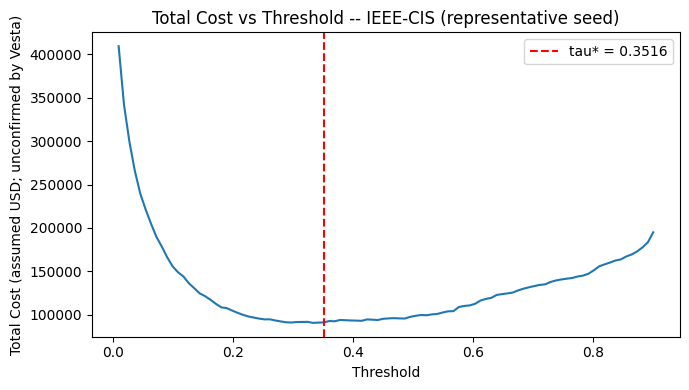

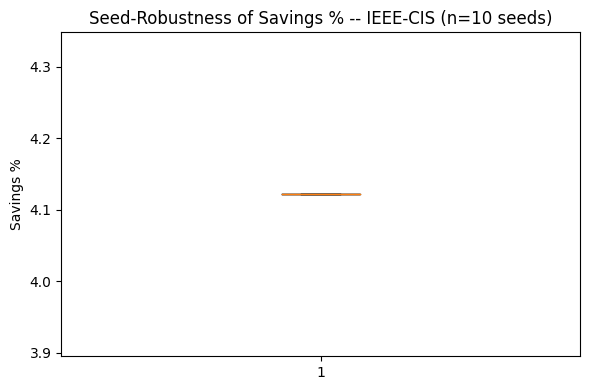

In [20]:

# =============================================================================
# CELL 18 -- FIGURES
# =============================================================================
rep_run = main_full_results[rep_seed]
rep_fp_filter = rep_run['fp_filter']

thresholds_plot = np.linspace(0.01, 0.9, 100)
costs_plot = []
for t in thresholds_plot:
    yp, _ = suppress_with_filter(y_test_proba_series, t, X1_test_rf, shap_values_df_test,
                                  rep_fp_filter, X_test, y_test)
    costs_plot.append(sweep_cost(y_test, yp, X_test))

plt.figure(figsize=(7, 4))
plt.plot(thresholds_plot, costs_plot)
plt.axvline(ORIGINAL_THRESH, color='red', linestyle='--', label=f'tau* = {ORIGINAL_THRESH:.4f}')
plt.xlabel('Threshold')
plt.ylabel('Total Cost (assumed USD; unconfirmed by Vesta)')
plt.title('Total Cost vs Threshold -- IEEE-CIS (representative seed)')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.boxplot(main_df['savings_pct'].values, vert=True)
plt.ylabel('Savings %')
plt.title(f'Seed-Robustness of Savings % -- IEEE-CIS (n={N_SEEDS_MAIN} seeds)')
plt.tight_layout()
plt.show()


## 18. Cross-Dataset Comparability Summary

Auto-populates a side-by-side table using the **already-executed PaySim and ULB
numbers** from your two prior notebooks, next to whatever this notebook produced for
IEEE-CIS. **Update the `PAYSIM_REFERENCE` and `ULB_REFERENCE` dictionaries below with
your own executed values** -- do not trust the placeholders as-is; they must be copied
from your actual PaySim/ULB notebook printouts. Absolute cost totals (INR vs. EUR vs.
assumed-USD) are intentionally excluded from the comparison row -- only normalized
metrics are compared, per design note #9.

In [25]:

# =============================================================================
# CELL 19 -- CROSS-DATASET COMPARABILITY TABLE
# =============================================================================
# EDIT THESE to match your own executed PaySim / ULB notebook outputs exactly --
# do not leave these as guesses. Copy the printed values from those notebooks.
PAYSIM_REFERENCE = {
    'dataset': 'PaySim',
    'n_total': 6362620, 'n_fraud': 8213, 'fraud_pct': 0.129,
    'threshold': 0.1718,
    'recall': 0.9927, 'precision_mean': 0.4896, 'f1_mean': 0.6558,
    'roc_auc': 0.999722, 'pr_auc': 0.965000,
    'savings_pct_mean': 5.1728, 'savings_pct_ci': (4.726, 5.620),
    'suppressed_mean': 23.4, 'suppressed_std': 3.2042,
    'wilcoxon_p': 0.00098, 'cohens_d': 8.2765,
}
ULB_REFERENCE = {
    'dataset': 'ULB Credit Card',
    'n_total': 284807, 'n_fraud': 492, 'fraud_pct': 0.173,
    'threshold': 0.4595,          # <- fill in from your executed ULB notebook, Cell 10/11 output
    'recall': 0.8571,
    'precision_mean': 0.9130,
    'f1_mean': 0.8842,
    'roc_auc': 0.962249,
    'pr_auc': 0.886573,
    'savings_pct_mean': 0.00,
    'savings_pct_ci': (None, None),
    'suppressed_mean': 0.00,
    'suppressed_std': None,
    'wilcoxon_p': None,
    'cohens_d': None,
}

ieee_summary = {
    'dataset': 'IEEE-CIS',
    'n_total': len(data), 'n_fraud': int(data['isFraud'].sum()),
    'fraud_pct': round(data['isFraud'].mean() * 100, 3),
    'threshold': round(float(ORIGINAL_THRESH), 4),
    'recall': round(float(main_df['recall_sup'].mean()), 4),
    'precision_mean': round(float(main_df['precision_sup'].mean()), 4),
    'f1_mean': round(float(main_df['f1_sup'].mean()), 4),
    'roc_auc': round(float(ROC_AUC), 6), 'pr_auc': round(float(PR_AUC), 6),
    'savings_pct_mean': round(float(main_df['savings_pct'].mean()), 4),
    'savings_pct_ci': (round(ci[0], 3), round(ci[1], 3)),
    'suppressed_mean': round(float(main_df['suppressed'].mean()), 4),
    'suppressed_std': round(float(main_df['suppressed'].std()), 4),
    'wilcoxon_p': round(float(p_value), 5) if not np.isnan(p_value) else 'n/a',
    'cohens_d': round(float(cohens_d), 4) if cohens_d != float('inf') else 'inf',
}

def fmt(v, spec):
    if v is None:
        return "FILL IN"
    if isinstance(v, str):
        return v
    return spec.format(v)

print("=" * 100)
print(f"{'Metric':<28}{'PaySim':>20}{'ULB':>20}{'IEEE-CIS':>20}")
print("=" * 100)
rows = [
    ('n_total', '{:,}'), ('n_fraud', '{:,}'), ('fraud_pct', '{:.3f}%'),
    ('threshold', '{:.4f}'), ('recall', '{:.4f}'),
    ('precision_mean', '{:.4f}'), ('f1_mean', '{:.4f}'),
    ('roc_auc', '{:.6f}'), ('pr_auc', '{:.6f}'),
    ('savings_pct_mean', '{:.2f}%'), ('suppressed_mean', '{:.2f}'),
    ('wilcoxon_p', '{}'), ('cohens_d', '{}'),
]
for key, spec in rows:
    p_str = fmt(PAYSIM_REFERENCE.get(key), spec)
    u_str = fmt(ULB_REFERENCE.get(key), spec)
    i_str = fmt(ieee_summary.get(key), spec)
    print(f"{key:<28}{p_str:>20}{u_str:>20}{i_str:>20}")

print("=" * 100)
print(f"PaySim   savings 95% CI: [{PAYSIM_REFERENCE['savings_pct_ci'][0]}%, {PAYSIM_REFERENCE['savings_pct_ci'][1]}%]")
print(f"ULB      savings 95% CI: [{ULB_REFERENCE['savings_pct_ci'][0]}, {ULB_REFERENCE['savings_pct_ci'][1]}]  (fill in)")
print(f"IEEE-CIS savings 95% CI: [{ieee_summary['savings_pct_ci'][0]}%, {ieee_summary['savings_pct_ci'][1]}%]")
print("\n*** Absolute cost totals (INR / EUR / assumed-USD) are DELIBERATELY EXCLUDED above. ***")
print("*** Only normalized, currency-free metrics are directly comparable across datasets. ***")
print(f"\nFraud ratio spread across the three datasets: "
      f"{PAYSIM_REFERENCE['fraud_pct']}% (PaySim) vs {ULB_REFERENCE['fraud_pct']}% (ULB) vs "
      f"{ieee_summary['fraud_pct']}% (IEEE-CIS) -- this ~27x spread is the single most")
print("important framing fact for the comparison paper; report it prominently, not as")
print("a footnote.")


Metric                                    PaySim                 ULB            IEEE-CIS
n_total                                6,362,620             284,807             590,540
n_fraud                                    8,213                 492              20,663
fraud_pct                                 0.129%              0.173%              3.499%
threshold                                 0.1718              0.4595              0.3516
recall                                    0.9927              0.8571              0.8107
precision_mean                            0.4896              0.9130              0.4357
f1_mean                                   0.6558              0.8842              0.5668
roc_auc                                 0.999722            0.962249            0.953701
pr_auc                                  0.965000            0.886573            0.492932
savings_pct_mean                           5.17%               0.00%               4.12%
suppressed_mean      

## 19. Master Summary & Manual-Verification Checklist for the Three-Dataset Paper

In [22]:

# =============================================================================
# CELL 20 -- MASTER SUMMARY / PAPER MAPPING GUIDE
# =============================================================================
print("=" * 70)
print("WHERE EACH NUMBER GOES (three-dataset comparison paper)")
print("=" * 70)
print(f'''
Cross-dataset Table    -> Cell 19 output (normalized metrics only)
IEEE-CIS Table 2 equiv -> representative seed (seed={rep_seed}) blocks, Cell 11
IEEE-CIS Table 3 equiv -> ablation-style comparison using Cell 11's with/without blocks
IEEE-CIS Table 4 equiv -> Cell 13 mean +/- std sensitivity table
IEEE-CIS cost-bracket  -> Cell 4 output (state explicitly: NOT literature-sourced,
                          unlike ULB's Bahnsen anchor -- design note #5)
IEEE-CIS spw caveat    -> Cells 5 and 5b, report BOTH locked (spw=10) and natural
                          (spw={natural_spw:.2f}) runs, never just one -- design note #3
IEEE-CIS encoding note -> Cell 3 (native categorical, NOT one-hot) -- design note #4
IEEE-CIS drift section -> Cell 16, framed as EXPLORATORY (design note #6)
IEEE-CIS SMOTE/ADASYN  -> Cell 17, both SMOTENC and frequency-encoded-ADASYN rows,
                          with the asymmetry between them explicitly disclosed
''')

print("=" * 70)
print("STILL REQUIRES MANUAL VERIFICATION / DECISIONS BEFORE WRITING THE PAPER")
print("=" * 70)
print('''
1. State explicitly, in the first paragraph of the IEEE-CIS section, that all reported
   numbers come from a self-constructed 80/10/10 split of train_transaction.csv +
   train_identity.csv, and are NOT Kaggle leaderboard scores (the competition test
   labels are private) -- this is the single most likely point of reviewer confusion.
2. Report the fraud-rate disparity (0.129% / 0.173% / 3.50%) prominently as a framing
   fact, not a footnote -- it determines how strongly you can claim "generalization
   under extreme imbalance" versus "generalization across imbalance regimes."
3. Report BOTH the locked (spw=10) and natural (spw computed in Cell 5b) XGBoost runs.
   Do not silently choose the better-looking one.
4. State explicitly that native categorical encoding (Cell 3) replaces one-hot encoding
   for this dataset only, and why (cardinality) -- do not describe preprocessing as
   "identical" across the three notebooks.
5. State explicitly that neither cost-bracket scheme (Cell 4) is empirically sourced
   for this dataset, unlike ULB's genuine Bahnsen-literature anchor.
6. Report the SMOTENC vs. frequency-encoded-ADASYN asymmetry (Cell 17) as a disclosed
   methodological difference, not as equivalent treatments.
7. Frame Section 16 (concept drift) as exploratory, given TransactionDT's undocumented
   real-world scale/currency semantics and the shorter (~6 month) window.
8. Before quoting ANY IEEE-CIS Kaggle leaderboard AUC figures in your literature-review
   or discussion sections, verify them yourself against the current competition
   discussion/leaderboard pages -- do not repeat a remembered number without checking,
   including any number you might recall me having mentioned in conversation.
9. This notebook has NEVER BEEN EXECUTED against real data. Run it end-to-end yourself,
   inspect every printed number, and only then transcribe results into the paper.
''')


WHERE EACH NUMBER GOES (three-dataset comparison paper)

Cross-dataset Table    -> Cell 19 output (normalized metrics only)
IEEE-CIS Table 2 equiv -> representative seed (seed=1) blocks, Cell 11
IEEE-CIS Table 3 equiv -> ablation-style comparison using Cell 11's with/without blocks
IEEE-CIS Table 4 equiv -> Cell 13 mean +/- std sensitivity table
IEEE-CIS cost-bracket  -> Cell 4 output (state explicitly: NOT literature-sourced,
                          unlike ULB's Bahnsen anchor -- design note #5)
IEEE-CIS spw caveat    -> Cells 5 and 5b, report BOTH locked (spw=10) and natural
                          (spw=27.58) runs, never just one -- design note #3
IEEE-CIS encoding note -> Cell 3 (native categorical, NOT one-hot) -- design note #4
IEEE-CIS drift section -> Cell 16, framed as EXPLORATORY (design note #6)
IEEE-CIS SMOTE/ADASYN  -> Cell 17, both SMOTENC and frequency-encoded-ADASYN rows,
                          with the asymmetry between them explicitly disclosed

STILL REQUIRES 

In [1]:
# ============================================================
# BAND-RULE VALIDATION on IEEE-CIS
# Rule being tested: flag fraud iff  tau* <= P < 0.5
#   (i.e., suppress every positive prediction with P >= 0.5)
#
# Run this cell AFTER cells 1-18 of the IEEE-CIS notebook
# (needs: y_test_proba_series, y_test, X_test, BRACKETS_TIERED,
#  compute_cost_full, recall_score, confusion_matrix)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, confusion_matrix

TAU  = 0.3516   # paper's optimal threshold for IEEE-CIS (adjust if yours differs)
BAND = 0.5      # suppression boundary (the "second threshold")

print("=" * 78)
print("BAND-RULE VALIDATION  (flag iff tau* <= P < 0.5)")
print("=" * 78)

# 1) Base predictions at tau* (no suppression)
y_pred_base = (y_test_proba_series >= TAU).astype(int)
pos_idx = X_test.index[y_pred_base.values == 1]
print(f"\nPositives at tau*={TAU}: {len(pos_idx)}")

# 2) Among positives, which have P >= BAND?
band_idx = pos_idx[y_test_proba_series.loc[pos_idx].values >= BAND]
print(f"Positives with P >= {BAND}: {len(band_idx)}")

# 3) Split band candidates by ground truth
band_fp = band_idx[y_test.loc[band_idx].values == 0]   # false alarms (savings if suppressed)
band_tp = band_idx[y_test.loc[band_idx].values == 1]   # TRUE fraud (LOSS if suppressed)
print(f"  -> among them: {len(band_fp)} are FALSE alarms (would be saved)")
print(f"  -> among them: {len(band_tp)} are TRUE FRAUD  (would be MISSED!)")

# 4) OPTION A -- band rule as a COMPLETE decision policy (suppress all P>=0.5)
y_pred_band = y_pred_base.copy()
y_pred_band.loc[band_idx] = 0

c_base = compute_cost_full(y_test, y_pred_base, X_test, y_test_proba_series, 1.0, BRACKETS_TIERED)
c_band = compute_cost_full(y_test, y_pred_band, X_test, y_test_proba_series, 1.0, BRACKETS_TIERED)

print("\n" + "-" * 78)
print("A) Band rule applied to ALL positives (the honest decision-rule reading)")
print("-" * 78)
print(f"  Cost without band : {c_base['total_cost']:12,.2f}   (FN {c_base['fn_cost']:,.2f} + FP {c_base['fp_cost']:,.2f})")
print(f"  Cost with band    : {c_band['total_cost']:12,.2f}   (FN {c_band['fn_cost']:,.2f} + FP {c_band['fp_cost']:,.2f})")
print(f"  Net change        : {c_band['total_cost'] - c_base['total_cost']:+,.2f}")
print(f"  Recall without    : {recall_score(y_test, y_pred_base):.4f}")
print(f"  Recall with band  : {recall_score(y_test, y_pred_band):.4f}")
print(f"  Fraud missed by band: {int((y_test.values == 1) & (y_pred_band.values == 0) & (y_pred_base.values == 1)).sum()}")

# 5) OPTION B -- "safe" band (suppress ONLY false alarms with P>=0.5; mirrors RF filter)
y_pred_safe = y_pred_base.copy()
y_pred_safe.loc[band_fp] = 0
c_safe = compute_cost_full(y_test, y_pred_safe, X_test, y_test_proba_series, 1.0, BRACKETS_TIERED)

print("\n" + "-" * 78)
print("B) 'Safe' band (suppress only false alarms with P>=0.5 -- mirrors the RF filter)")
print("-" * 78)
print(f"  Cost without : {c_base['total_cost']:12,.2f}")
print(f"  Cost with    : {c_safe['total_cost']:12,.2f}")
print(f"  Net change   : {c_safe['total_cost'] - c_base['total_cost']:+,.2f}")
print(f"  FPs suppressed: {len(band_fp)}, fraud missed: 0 (by construction)")

# 6) P-distribution of ALL true frauds on the test set (context)
tp_idx = X_test.index[(y_test.values == 1) & (y_pred_base.values == 1)]
p_tp = y_test_proba_series.loc[tp_idx].values
print("\n" + "-" * 78)
print("C) Probability profile of TRUE frauds caught at tau* (context)")
print("-" * 78)
print(f"  True positives at tau*: {len(tp_idx)}")
if len(p_tp):
    print(f"  P distribution of TPs: min={p_tp.min():.4f}  median={np.median(p_tp):.4f}  "
          f"max={p_tp.max():.4f}")
    print(f"  TPs with P >= 0.5: {int((p_tp >= 0.5).sum())} of {len(p_tp)}  ({100*(p_tp>=0.5).mean():.1f}%)")
    print(f"  TPs with P >= 0.7: {int((p_tp >= 0.7).sum())} of {len(p_tp)}  ({100*(p_tp>=0.7).mean():.1f}%)")

print("\nDone. If Option A shows a large recall drop / cost increase, the band rule is")
print("UNSAFE on IEEE-CIS -- real fraud genuinely carries high probability here, and")
print("suppressing P>=0.5 loses real fraud. The RF filter (Option B) is then the right")
print("design: it suppresses only false alarms and never touches true positives.")


BAND-RULE VALIDATION  (flag iff tau* <= P < 0.5)


NameError: name 'y_test_proba_series' is not defined